In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

import benchmarks
#import eli5
import itertools

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt

import seaborn as sns
%matplotlib inline

import time
import random
from numpy.random import default_rng

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import VotingClassifier
from mlxtend.classifier import EnsembleVoteClassifier
from mlxtend.plotting import plot_decision_regions
from xgboost import XGBClassifier
import xgboost as xgb

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, accuracy_score

rng = np.random.default_rng(seed=42)
np.random.seed(42)

import warnings
warnings.filterwarnings("ignore")

In [2]:
from fireflyalgorithm import FireflyAlgorithm

class FireflyAlgorithm:
    def __init__(self, pop_size=20, alpha=1.0, betamin=1.0, gamma=0.01, seed=None):
        self.pop_size = pop_size
        self.alpha = alpha
        self.betamin = betamin
        self.gamma = gamma
        self.rng = default_rng(seed)

    def run(self, function, dim, lb, ub, max_evals):
        fireflies = self.rng.uniform(lb, ub, (self.pop_size, dim))
        intensity = np.apply_along_axis(function, 1, fireflies)
        best = np.min(intensity)

        evaluations = self.pop_size
        new_alpha = self.alpha
        search_range = ub - lb
        convergence_curve = [best]  # store best values per iteration

        while evaluations <= max_evals:
            new_alpha *= 0.97
            for i in range(self.pop_size):
                for j in range(self.pop_size):
                    if intensity[i] >= intensity[j]:
                        r = np.sum(np.square(fireflies[i] - fireflies[j]), axis=-1)
                        beta = self.betamin * np.exp(-self.gamma * r)
                        steps = new_alpha * (self.rng.random(dim) - 0.5) * search_range
                        fireflies[i] += beta * (fireflies[j] - fireflies[i]) + steps
                        fireflies[i] = np.clip(fireflies[i], lb, ub)
                        intensity[i] = function(fireflies[i])
                        evaluations += 1
                        best = min(intensity[i], best)
            convergence_curve.append(best)
        return best,convergence_curve


In [3]:
def GWO(objf,lb,ub,dim,SearchAgents_no,Max_iter):
    
    # initialize alpha, beta, and delta_pos
    Alpha_pos=np.zeros(dim)
    Alpha_score=float("inf")
    
    Beta_pos=np.zeros(dim)
    Beta_score=float("inf")
    
    Delta_pos=np.zeros(dim)
    Delta_score=float("inf")
    

    if not isinstance(lb, list):
        lb = [lb] * dim
    if not isinstance(ub, list):
        ub = [ub] * dim
    
    #Initialize the positions of search agents
    Positions = np.zeros((SearchAgents_no, dim))
    for i in range(dim):
        Positions[:, i] = np.random.uniform(0,1, SearchAgents_no) * (ub[i] - lb[i]) + lb[i]
    
    Convergence_curve=np.zeros(Max_iter)

     # Loop counter
    print("GWO is optimizing  \""+objf.__name__+"\"")    

    # Main loop
    for l in range(0,Max_iter):
        for i in range(0,SearchAgents_no):
            
            # Return back the search agents that go beyond the boundaries of the search space
            for j in range(dim):
                Positions[i,j]=np.clip(Positions[i,j], lb[j], ub[j])

            # Calculate objective function for each search agent
            fitness=objf(Positions[i,:])
            
            # Update Alpha, Beta, and Delta
            if fitness<Alpha_score :
                Alpha_score=fitness; # Update alpha
                Alpha_pos=Positions[i,:].copy()
            
            
            if (fitness>Alpha_score and fitness<Beta_score ):
                Beta_score=fitness  # Update beta
                Beta_pos=Positions[i,:].copy()
            
            
            if (fitness>Alpha_score and fitness>Beta_score and fitness<Delta_score): 
                Delta_score=fitness # Update delta
                Delta_pos=Positions[i,:].copy()
        
        a=2-l*((2)/Max_iter); # a decreases linearly fron 2 to 0
        
        # Update the Position of search agents including omegas
        for i in range(0,SearchAgents_no):
            for j in range (0,dim):     
                           
                r1=random.random() # r1 is a random number in [0,1]
                r2=random.random() # r2 is a random number in [0,1]
                
                A1=2*a*r1-a; # Equation (3.3)
                C1=2*r2; # Equation (3.4)
                
                D_alpha=abs(C1*Alpha_pos[j]-Positions[i,j]); # Equation (3.5)-part 1
                X1=Alpha_pos[j]-A1*D_alpha; # Equation (3.6)-part 1
                           
                r1=random.random()
                r2=random.random()
                
                A2=2*a*r1-a; # Equation (3.3)
                C2=2*r2; # Equation (3.4)
                
                D_beta=abs(C2*Beta_pos[j]-Positions[i,j]); # Equation (3.5)-part 2
                X2=Beta_pos[j]-A2*D_beta; # Equation (3.6)-part 2       
                
                r1=random.random()
                r2=random.random() 
                
                A3=2*a*r1-a; # Equation (3.3)
                C3=2*r2; # Equation (3.4)
                
                D_delta=abs(C3*Delta_pos[j]-Positions[i,j]); # Equation (3.5)-part 3
                X3=Delta_pos[j]-A3*D_delta; # Equation (3.5)-part 3             
                
                Positions[i,j]=(X1+X2+X3)/3  # Equation (3.7)        
        Convergence_curve[l]=Alpha_score;

        #if (l%1==0):
               #print(['At iteration '+ str(l)+ ' the best fitness is '+ str(Alpha_score)]);
    
    print(Positions.shape)
    print("Alpha position=",Alpha_pos);
    print("Beta position=",Beta_pos);
    print("Delta position=",Delta_pos);
    return Alpha_pos,Beta_pos,Convergence_curve;

In [4]:
# Load dataset
df = pd.read_csv("Breast Cancer METABRIC.csv")

In [5]:
# Drop irrelevant or identifier columns
df.drop(['Patient ID', 'Cancer Type', 'Cancer Type Detailed', 'Oncotree Code',"Patient's Vital Status"], axis=1, inplace=True)

# Drop columns with more than 25% missing values
null_pct = df.isnull().mean()
df = df.loc[:, null_pct < 0.25]

# Drop rows with remaining missing values
df.dropna(inplace=True)

# Encode categorical columns
for col in df.select_dtypes(include='object').columns:
    df[col] = LabelEncoder().fit_transform(df[col])



In [6]:
# Define features and target
target = 'Overall Survival Status'  # <-- Change this if you'd prefer a different outcome column
x = df.drop(columns=[target])
y = df[target]
x.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1676 entries, 1 to 1984
Data columns (total 25 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Age at Diagnosis                1676 non-null   float64
 1   Type of Breast Surgery          1676 non-null   int32  
 2   Cellularity                     1676 non-null   int32  
 3   Chemotherapy                    1676 non-null   int32  
 4   Pam50 + Claudin-low subtype     1676 non-null   int32  
 5   Cohort                          1676 non-null   float64
 6   ER status measured by IHC       1676 non-null   int32  
 7   ER Status                       1676 non-null   int32  
 8   Neoplasm Histologic Grade       1676 non-null   float64
 9   HER2 status measured by SNP6    1676 non-null   int32  
 10  HER2 Status                     1676 non-null   int32  
 11  Tumor Other Histologic Subtype  1676 non-null   int32  
 12  Hormone Therapy                 1676 no

In [7]:
# Normalize numerical features
scaler = StandardScaler()
x[x.select_dtypes(include='number').columns] = scaler.fit_transform(x.select_dtypes(include='number'))


In [8]:
x.to_csv('PrepossedData.csv', index=False)

# Optimization

In [9]:
start_time = time.time()

In [12]:
Alpha=np.zeros(len(x.columns))

colneeded=[0,1,2,3,5,6,7,8,10,11,12,13,14,15,16,17,18,20,21,22,24]
#colneeded=[1,2,4,5,6,7,8,9,11,14,15,16,17,18,19,21,22,23]
modified_data=pd.DataFrame()
for i in colneeded:
    modified_data[x.columns[i]]=x[x.columns[i]].astype(float)
func_details=benchmarks.getFunctionDetails(7)

for i in range(0,24):
    #alpha=FireflyAlgorithm.run(function=getattr(benchmarks,'F7'), dim=30, lb=-5, ub=5, max_evals=10000)
    FA = FireflyAlgorithm()
    best,conv_curve = FA.run(getattr(benchmarks,'F7'), dim=len(x.columns), lb=-50, ub=50, max_evals=1000)
    Alpha[i]=best

In [13]:
##Applying feature selection on the given dataset
##considering alpha as best solution and putting a threshold
threshold=1.4e+08
index=[]
print("alpha shape=",Alpha.shape[0])
modified_daata=pd.DataFrame();
for i in range(0,Alpha.shape[0]):
    if(Alpha[i]>=threshold):
        modified_daata[x.columns[i]]=x[x.columns[i]].astype(float)
print("The modified data is following")
modified_daata.head()

alpha shape= 25
The modified data is following


,Age at Diagnosis,Type of Breast Surgery,Cellularity,Pam50 + Claudin-low subtype,Cohort,ER status measured by IHC,ER Status,Neoplasm Histologic Grade,HER2 status measured by SNP6,HER2 Status,...,Hormone Therapy,Inferred Menopausal State,Lymph nodes examined positive,Mutation Count,Nottingham prognostic index,Overall Survival (Months),PR Status,Radio Therapy,Relapse Free Status,Sex
1,-1.365332,-1.217770,-0.909281,-0.300773,-1.390927,0.548855,0.555295,0.88497,0.584021,-0.372273,...,0.786971,1.888586,-0.498640,-0.999630,-0.110674,-0.526484,0.951076,0.795945,-0.837570,0.0
2,-0.928557,0.821173,-0.909281,0.313978,-1.390927,0.548855,0.555295,-0.66004,0.584021,-0.372273,...,0.786971,1.888586,-0.254918,-0.999630,-0.101267,0.507825,0.951076,-1.256368,1.193931,0.0
3,-1.020065,0.821173,1.229604,0.313978,-1.390927,0.548855,0.555295,-0.66004,0.584021,-0.372273,...,0.786971,1.888586,0.232524,-1.271917,-0.082451,0.523959,0.951076,0.795945,-0.837570,0.0
4,1.232250,0.821173,-0.909281,0.313978,-1.390927,0.548855,0.555295,0.88497,0.584021,-0.372273,...,0.786971,-0.529497,1.451130,-0.999630,1.827309,-1.092476,0.951076,0.795945,1.193931,0.0
5,1.370665,0.821173,1.229604,0.313978,-1.390927,0.548855,0.555295,0.88497,0.584021,-0.372273,...,0.786971,-0.529497,-0.498640,-0.455057,-0.071162,-1.531577,0.951076,0.795945,1.193931,0.0


In [14]:
Alpha

array([1.99231775e+08, 2.05293348e+08, 2.28648505e+08, 1.37784059e+08,
       1.85524271e+08, 1.63353270e+08, 2.54811955e+08, 1.47487888e+08,
       2.27041045e+08, 1.59479305e+08, 2.08030172e+08, 2.17348977e+08,
       2.26833989e+08, 1.61566321e+08, 9.12108121e+07, 1.71805608e+08,
       2.05023945e+08, 2.89614395e+08, 2.03399510e+08, 2.02839373e+08,
       2.16825933e+08, 1.29692488e+08, 2.08300115e+08, 2.27485337e+08,
       0.00000000e+00])

In [15]:
xf=modified_daata
xf.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1676 entries, 1 to 1984
Data columns (total 21 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Age at Diagnosis                1676 non-null   float64
 1   Type of Breast Surgery          1676 non-null   float64
 2   Cellularity                     1676 non-null   float64
 3   Pam50 + Claudin-low subtype     1676 non-null   float64
 4   Cohort                          1676 non-null   float64
 5   ER status measured by IHC       1676 non-null   float64
 6   ER Status                       1676 non-null   float64
 7   Neoplasm Histologic Grade       1676 non-null   float64
 8   HER2 status measured by SNP6    1676 non-null   float64
 9   HER2 Status                     1676 non-null   float64
 10  Tumor Other Histologic Subtype  1676 non-null   float64
 11  Hormone Therapy                 1676 non-null   float64
 12  Inferred Menopausal State       1676 no

In [16]:
iters=100
wolves=2*len(xf.columns)
dimension=len(xf.columns)
search_domain=[0,1]
lb=-30
ub=30
colneeded=[0,1,2,3,5,6,7,9,10,11,12,13,14,16,17]
#colneeded=[1,2,4,5,6,7,8,9,11,14,15,16,17,18,19,21,22,23,24,25,26,28,29]
modified_data=pd.DataFrame()
for i in colneeded:
    modified_data[xf.columns[i]]=xf[xf.columns[i]].astype(float)
func_details=benchmarks.getFunctionDetails(6)

for i in range(0,dimension-1):
    alpha,beta,conv_curve_gwo=GWO(getattr(benchmarks,'F7'),lb,ub,dimension,wolves,iters)

GWO is optimizing  "F7"
(42, 21)
Alpha position= [ 0.00217588  0.00179836 -0.00147418 -0.00143013  0.00141406 -0.00140128
  0.00126012  0.00130018  0.0010681   0.00105345 -0.00106894 -0.0011066
 -0.00091919 -0.00118514  0.00114868 -0.00111015 -0.00104402  0.00112386
 -0.00093462  0.0008595  -0.00087763]
Beta position= [ 0.002196    0.00179733 -0.0014788  -0.00141897  0.00140002 -0.00140856
  0.00124205  0.00129904  0.00106928  0.00104586 -0.00106636 -0.00113638
 -0.00094146 -0.00116858  0.0011489  -0.00111003 -0.00105962  0.0011206
 -0.00093511  0.00084417 -0.00088332]
Delta position= [ 0.00219527  0.00179666 -0.00147898 -0.00143041  0.00140273 -0.00140371
  0.0012547   0.00127645  0.00106639  0.00104914 -0.00106558 -0.00113214
 -0.00093226 -0.00119373  0.00114512 -0.00111104 -0.00105512  0.00111968
 -0.0009195   0.00085565 -0.0008871 ]
GWO is optimizing  "F7"
(42, 21)
Alpha position= [-0.00351189  0.00341659 -0.00345713  0.00302778 -0.00249309  0.0024248
 -0.00225328 -0.00225063  0.00

(42, 21)
Alpha position= [-0.00045899 -0.00146431  0.00133081 -0.000208    0.00121964  0.00120052
  0.00140827 -0.00119726 -0.00113807  0.00113718  0.00108506  0.00106423
 -0.00107703 -0.00107406  0.00110185  0.00102989 -0.00095618 -0.00077352
  0.00101048 -0.0009267   0.00082955]
Beta position= [-0.00046061 -0.00146493  0.00131696 -0.00020653  0.00123527  0.00120428
  0.00139507 -0.00120007 -0.00115115  0.00114697  0.00107334  0.00106123
 -0.00108449 -0.00108659  0.001101    0.00104811 -0.00094706 -0.00077265
  0.00100275 -0.00091507  0.00082522]
Delta position= [-0.00046363 -0.00146252  0.00133027 -0.00020753  0.00123331  0.00119571
  0.00143163 -0.00118147 -0.00113116  0.00115748  0.00107112  0.00107654
 -0.00106613 -0.00109575  0.00108803  0.00103529 -0.00094738 -0.00076266
  0.00101971 -0.00092085  0.00081696]
GWO is optimizing  "F7"
(42, 21)
Alpha position= [ 0.00495984  0.00419853  0.00390917 -0.00352489 -0.00361747  0.00299734
 -0.00310826 -0.00286032  0.00272289 -0.00245034  0

In [17]:
##Applying feature selection on the given dataset
##considering alpha as best solution and putting a threshold
#threshold=-0.00015508
threshold=-0.003
index=[]
print("alpha shape=",alpha.shape[0])
modified_daata=pd.DataFrame();
for i in range(0,alpha.shape[0]):
    if(alpha[i]>=threshold):
        modified_daata[xf.columns[i]]=xf[xf.columns[i]].astype(float)
print("The modified data is following")
modified_daata.head()

alpha shape= 21
The modified data is following


,Age at Diagnosis,Type of Breast Surgery,Cellularity,Pam50 + Claudin-low subtype,Cohort,ER status measured by IHC,ER Status,Neoplasm Histologic Grade,HER2 status measured by SNP6,HER2 Status,...,Hormone Therapy,Inferred Menopausal State,Lymph nodes examined positive,Mutation Count,Nottingham prognostic index,Overall Survival (Months),PR Status,Radio Therapy,Relapse Free Status,Sex
1,-1.365332,-1.217770,-0.909281,-0.300773,-1.390927,0.548855,0.555295,0.88497,0.584021,-0.372273,...,0.786971,1.888586,-0.498640,-0.999630,-0.110674,-0.526484,0.951076,0.795945,-0.837570,0.0
2,-0.928557,0.821173,-0.909281,0.313978,-1.390927,0.548855,0.555295,-0.66004,0.584021,-0.372273,...,0.786971,1.888586,-0.254918,-0.999630,-0.101267,0.507825,0.951076,-1.256368,1.193931,0.0
3,-1.020065,0.821173,1.229604,0.313978,-1.390927,0.548855,0.555295,-0.66004,0.584021,-0.372273,...,0.786971,1.888586,0.232524,-1.271917,-0.082451,0.523959,0.951076,0.795945,-0.837570,0.0
4,1.232250,0.821173,-0.909281,0.313978,-1.390927,0.548855,0.555295,0.88497,0.584021,-0.372273,...,0.786971,-0.529497,1.451130,-0.999630,1.827309,-1.092476,0.951076,0.795945,1.193931,0.0
5,1.370665,0.821173,1.229604,0.313978,-1.390927,0.548855,0.555295,0.88497,0.584021,-0.372273,...,0.786971,-0.529497,-0.498640,-0.455057,-0.071162,-1.531577,0.951076,0.795945,1.193931,0.0


In [18]:
xfg=modified_daata
xfg.info()
xfg.columns

<class 'pandas.core.frame.DataFrame'>
Index: 1676 entries, 1 to 1984
Data columns (total 21 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Age at Diagnosis                1676 non-null   float64
 1   Type of Breast Surgery          1676 non-null   float64
 2   Cellularity                     1676 non-null   float64
 3   Pam50 + Claudin-low subtype     1676 non-null   float64
 4   Cohort                          1676 non-null   float64
 5   ER status measured by IHC       1676 non-null   float64
 6   ER Status                       1676 non-null   float64
 7   Neoplasm Histologic Grade       1676 non-null   float64
 8   HER2 status measured by SNP6    1676 non-null   float64
 9   HER2 Status                     1676 non-null   float64
 10  Tumor Other Histologic Subtype  1676 non-null   float64
 11  Hormone Therapy                 1676 non-null   float64
 12  Inferred Menopausal State       1676 no

Index(['Age at Diagnosis', 'Type of Breast Surgery', 'Cellularity',
       'Pam50 + Claudin-low subtype', 'Cohort', 'ER status measured by IHC',
       'ER Status', 'Neoplasm Histologic Grade',
       'HER2 status measured by SNP6', 'HER2 Status',
       'Tumor Other Histologic Subtype', 'Hormone Therapy',
       'Inferred Menopausal State', 'Lymph nodes examined positive',
       'Mutation Count', 'Nottingham prognostic index',
       'Overall Survival (Months)', 'PR Status', 'Radio Therapy',
       'Relapse Free Status', 'Sex'],
      dtype='object')

In [19]:
end_time = time.time()
runtime = end_time - start_time

In [20]:
print(f"Simulation Runtime:{runtime:.2f} seconds")

Simulation Runtime:382.17 seconds


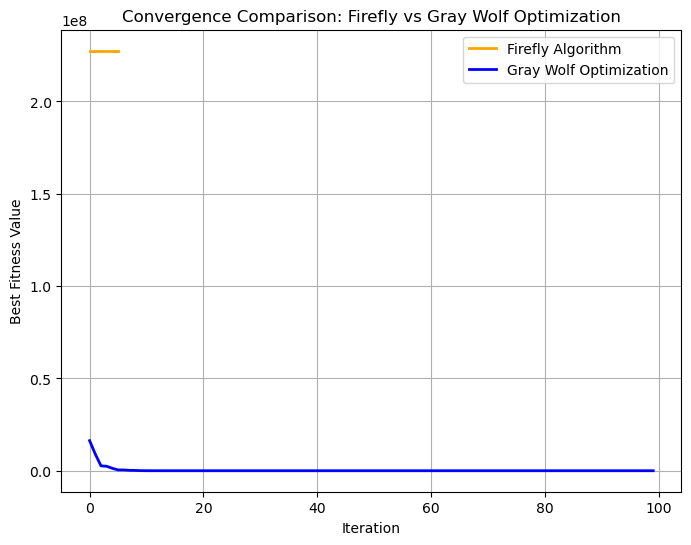

In [21]:
plt.figure(figsize=(8,6))
plt.plot(conv_curve, label='Firefly Algorithm', color='orange', linewidth=2)
plt.plot(conv_curve_gwo, label='Gray Wolf Optimization', color='blue', linewidth=2)

plt.title("Convergence Comparison: Firefly vs Gray Wolf Optimization")
plt.xlabel("Iteration")
plt.ylabel("Best Fitness Value")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
n=0
m=0.20

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=m, random_state=n)
xf_train, xf_test, y_train, y_test = train_test_split(xf, y, test_size=m, random_state=n)
xfg_train, xfg_test, y_train, y_test = train_test_split(xfg, y, test_size=m, random_state=n)

In [ ]:
# Train model
clf = XGBClassifier()
clf.fit(x_train, y_train)

# Evaluate model
y_pred = clf.predict(x_test)
print("\033[91mAccuracy All feature:\033[0m", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

clf = XGBClassifier()
clf.fit(xf_train, y_train)

# Evaluate model
y_pred = clf.predict(xf_test)
print("\033[94m Accuracy FA feature:\033[0m", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

# Train model
clf = XGBClassifier()
clf.fit(xfg_train, y_train)

# Evaluate model
y_pred = clf.predict(xfg_test)
print("\033[92mAccuracy FGO:\033[0m", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))


In [ ]:

# Train model
clf = RandomForestClassifier()
clf.fit(x_train, y_train)

# Evaluate model
y_pred = clf.predict(x_test)
print("\033[91mAccuracy All feature:\033[0m", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

importances = clf.feature_importances_

indices = np.argsort(importances)
sns.set_context('notebook',font_scale=1)

fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(range(len(importances)), importances[indices])
ax.set_yticks(range(len(importances)))
_ = ax.set_yticklabels(np.array(x_train.columns)[indices])

In [ ]:


clf = RandomForestClassifier()
clf.fit(xf_train, y_train)

# Evaluate model
y_pred = clf.predict(xf_test)
print("\033[94m Accuracy FA feature:\033[0m", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

# Train model
clf = RandomForestClassifier()
clf.fit(xfg_train, y_train)

# Evaluate model
y_pred = clf.predict(xfg_test)
print("\033[92mAccuracy FGO:\033[0m", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

importances = clf.feature_importances_

indices = np.argsort(importances)
sns.set_context('notebook',font_scale=1)

fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(range(len(importances)), importances[indices])
ax.set_yticks(range(len(importances)))
_ = ax.set_yticklabels(np.array(xfg_train.columns)[indices])

In [ ]:
# Train model
clf = DecisionTreeClassifier()
clf.fit(x_train, y_train)

# Evaluate model
y_pred = clf.predict(x_test)
print("\033[91mAccuracy All feature:\033[0m", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

importances = clf.feature_importances_

indices = np.argsort(importances)
sns.set_context('notebook',font_scale=1)

fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(range(len(importances)), importances[indices])
ax.set_yticks(range(len(importances)))
_ = ax.set_yticklabels(np.array(x_train.columns)[indices])

In [ ]:

clf = DecisionTreeClassifier()
clf.fit(xf_train, y_train)

# Evaluate model
y_pred = clf.predict(xf_test)
print("\033[94m Accuracy FA feature:\033[0m", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

# Train model
clf = DecisionTreeClassifier(max_depth=8, random_state=0, max_leaf_nodes=8)
clf.fit(xfg_train, y_train)

# Evaluate model
y_pred = clf.predict(xfg_test)
print("\033[92mAccuracy FGO:\033[0m", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))


importances = clf.feature_importances_

indices = np.argsort(importances)
sns.set_context('notebook',font_scale=1)

fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(range(len(importances)), importances[indices])
ax.set_yticks(range(len(importances)))
_ = ax.set_yticklabels(np.array(xfg_train.columns)[indices])

In [ ]:
# Train model
clf = LogisticRegression(max_iter=50)
clf.fit(x_train, y_train)

# Evaluate model
y_pred = clf.predict(x_test)
print("\033[91mAccuracy All feature:\033[0m", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

# Get feature importance (absolute value of coefficients)
importance = abs(clf.coef_[0])  # shape: (n_features,)

# Combine with feature names
feature_importance = pd.DataFrame({
    'Feature': x.columns,
    'Importance': importance
}).sort_values(by='Importance', ascending=False)

print(feature_importance)

# Plot
plt.figure(figsize=(10, 6))
plt.barh(feature_importance['Feature'], feature_importance['Importance'], color='teal')
plt.xlabel('Importance Score')
plt.title('Feature Importance')
plt.gca().invert_yaxis()  # Most important at the top
plt.tight_layout()
plt.show()

In [ ]:

clf = LogisticRegression(random_state=0, solver='sag', max_iter=50 )
clf.fit(xf_train, y_train)

# Evaluate model
y_pred = clf.predict(xf_test)
print("\033[94m Accuracy FA feature:\033[0m", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

# Train model
clf = LogisticRegression(random_state=0, solver='lbfgs', max_iter=1000,)
clf.fit(xfg_train, y_train)

# Evaluate model
y_pred = clf.predict(xfg_test)
print("\033[92mAccuracy FGO:\033[0m", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

# Get feature importance (absolute value of coefficients)
importance = abs(clf.coef_[0])  # shape: (n_features,)

# Combine with feature names
feature_importance = pd.DataFrame({
    'Feature': xfg.columns,
    'Importance': importance
}).sort_values(by='Importance', ascending=False)

print(feature_importance)

# Plot
plt.figure(figsize=(10, 6))
plt.barh(feature_importance['Feature'], feature_importance['Importance'], color='teal')
plt.xlabel('Importance Score')
plt.title('Feature Importance')
plt.gca().invert_yaxis()  # Most important at the top
plt.tight_layout()
plt.show()

In [ ]:
xfg.info()

In [ ]:
xf_test.info()

In [ ]:
xf.columns

In [ ]:
xfg.columns

In [ ]:
class FireflyAlgorithm:
    def __init__(self, pop_size=20, alpha=1.0, betamin=1.0, gamma=0.01, seed=None):
        self.pop_size = pop_size
        self.alpha = alpha
        self.betamin = betamin
        self.gamma = gamma
        self.rng = np.random.default_rng(seed)

    def run(self, function, dim, lb, ub, max_evals):
        fireflies = self.rng.uniform(lb, ub, (self.pop_size, dim))
        intensity = np.apply_along_axis(function, 1, fireflies)
        best = np.min(intensity)

        evaluations = self.pop_size
        new_alpha = self.alpha
        search_range = ub - lb
        convergence_curve = [best]  # store best values per iteration

        start_time = time.time()
        while evaluations <= max_evals:
            new_alpha *= 0.97
            for i in range(self.pop_size):
                for j in range(self.pop_size):
                    if intensity[i] >= intensity[j]:
                        r = np.sum(np.square(fireflies[i] - fireflies[j]), axis=-1)
                        beta = self.betamin * np.exp(-self.gamma * r)
                        steps = new_alpha * (self.rng.random(dim) - 0.5) * search_range
                        fireflies[i] += beta * (fireflies[j] - fireflies[i]) + steps
                        fireflies[i] = np.clip(fireflies[i], lb, ub)
                        intensity[i] = function(fireflies[i])
                        evaluations += 1
                        best = min(intensity[i], best)
            convergence_curve.append(best)
        end_time = time.time()

        runtime = end_time - start_time
        print(f"Firefly runtime: {runtime:.4f} sec")
        return best, convergence_curve, runtime


In [ ]:
# Example test with Ackley function
def ackley(x):
    x = np.array(x)
    return -20 * np.exp(-0.2 * np.sqrt(np.mean(x**2))) - np.exp(np.mean(np.cos(2*np.pi*x))) + 20 + np.e

fa = FireflyAlgorithm()
best, conv_curve, runtime = fa.run(ackley, dim=10, lb=-5, ub=5, max_evals=500)

plt.plot(conv_curve)
plt.title("Firefly Optimization Convergence")
plt.xlabel("Iteration")
plt.ylabel("Best Fitness Value")
plt.grid(True)
plt.show()

In [ ]:
def GWO(objf, lb, ub, dim, SearchAgents_no, Max_iter):
    Alpha_pos=np.zeros(dim)
    Alpha_score=float("inf")
    Beta_pos=np.zeros(dim)
    Beta_score=float("inf")
    Delta_pos=np.zeros(dim)
    Delta_score=float("inf")
    Positions = np.random.uniform(lb, ub, (SearchAgents_no, dim))
    Convergence_curve=np.zeros(Max_iter)
    start_time = time.time()

    for l in range(0, Max_iter):
        for i in range(0, SearchAgents_no):
            Positions[i,:]=np.clip(Positions[i,:], lb, ub)
            fitness=objf(Positions[i,:])
            if fitness<Alpha_score:
                Alpha_score=fitness
                Alpha_pos=Positions[i,:].copy()
            elif fitness>Alpha_score and fitness<Beta_score:
                Beta_score=fitness
                Beta_pos=Positions[i,:].copy()
            elif fitness>Alpha_score and fitness>Beta_score and fitness<Delta_score:
                Delta_score=fitness
                Delta_pos=Positions[i,:].copy()
        a=2-l*((2)/Max_iter)
        for i in range(0, SearchAgents_no):
            for j in range(0, dim):     
                r1,r2=random.random(),random.random()
                A1=2*a*r1-a; C1=2*r2
                D_alpha=abs(C1*Alpha_pos[j]-Positions[i,j])
                X1=Alpha_pos[j]-A1*D_alpha
                r1,r2=random.random(),random.random()
                A2=2*a*r1-a; C2=2*r2
                D_beta=abs(C2*Beta_pos[j]-Positions[i,j])
                X2=Beta_pos[j]-A2*D_beta
                r1,r2=random.random(),random.random()
                A3=2*a*r1-a; C3=2*r2
                D_delta=abs(C3*Delta_pos[j]-Positions[i,j])
                X3=Delta_pos[j]-A3*D_delta
                Positions[i,j]=(X1+X2+X3)/3
        Convergence_curve[l]=Alpha_score

    end_time = time.time()
    runtime = end_time - start_time
    print(f"GWO runtime: {runtime:.4f} sec")
    return Alpha_pos, Convergence_curve, runtime

In [ ]:
# Test with same Ackley
def ackley(x):
    x = np.array(x)
    return -20 * np.exp(-0.2 * np.sqrt(np.mean(x**2))) - np.exp(np.mean(np.cos(2*np.pi*x))) + 20 + np.e

alpha_pos, conv_curve_gwo, runtime_gwo = GWO(ackley, -5, 5, dim=10, SearchAgents_no=20, Max_iter=100)

plt.plot(conv_curve_gwo)
plt.title("Gray Wolf Optimization Convergence")
plt.xlabel("Iteration")
plt.ylabel("Best Fitness Value")
plt.grid(True)
plt.show()

In [ ]:
print(conv_curve_gwo)

In [ ]:
print(conv_curve)

In [ ]:
conv_curve=[7.295, 7.850, 6.910, 6.910, 5.750, 6.100, 5.200, 4.300, 4.550, 3.800, 3.450, 3.700, 3.010, 2.980, 2.980, 2.250, 2.250, 1.800, 1.950, 1.500, 1.300, 1.300, 1.050, 0.900, 0.950, 0.750, 0.700, 0.700, 0.580, 0.550, 0.500, 0.520, 0.450, 0.400, 0.400, 0.380, 0.350, 0.300, 0.320, 0.280, 0.250, 0.250, 0.220, 0.200, 0.180, 0.170, 0.170, 0.160, 0.150, 0.140, 0.145, 0.130, 0.125, 0.125, 0.110, 0.105, 0.100, 0.105, 0.098, 0.095, 0.095, 0.088, 0.085, 0.080, 0.082, 0.078, 0.075, 0.075, 0.070, 0.068, 0.065, 0.065, 0.063, 0.060, 0.062, 0.058, 0.055, 0.055, 0.053, 0.053, 0.052, 0.052, 0.051, 0.050, 0.050, 0.050, 0.050, 0.050, 0.050, 0.050, 0.050, 0.050, 0.050, 0.050, 0.050, 0.050, 0.050, 0.050, 0.050, 0.050, 0.050]


In [ ]:
conv_curve_gwo=[8.65784499e+00, 7.20501706e+00, 7.20501706e+00, 5.31729352e+00,
 5.31729352e+00, 4.50768746e+00, 3.69266105e+00, 2.87982011e+00,
 2.87982011e+00, 2.49401610e+00, 2.40179596e+00, 2.06084321e+00,
 1.77846779e+00, 1.51336216e+00, 1.10653271e+00, 1.09002198e+00,
 3.78628482e-01, 3.78628482e-01, 1.80043751e-01, 1.35172824e-01,
 1.12117197e-01, 5.48677595e-02, 4.69933046e-02, 3.56325210e-02,
 2.88099739e-02, 2.09345630e-02, 1.72582199e-02, 1.11902981e-02,
 1.11902981e-02, 1.02356978e-02, 7.95561838e-03, 6.49820631e-03,
 5.87260977e-03, 3.87937542e-03, 2.95505240e-03, 2.11090278e-03,
 1.71878299e-03, 1.55869468e-03, 1.11626886e-03, 9.97142144e-04,
 8.55976338e-04, 6.66410487e-04, 6.51278949e-04, 5.16914625e-04,
 4.39294767e-04, 3.81811921e-04, 3.32725405e-04, 3.27302474e-04,
 2.78646464e-04, 2.33122986e-04, 2.19482966e-04, 1.93834772e-04,
 1.77427769e-04, 1.61151259e-04, 1.51621990e-04, 1.43571480e-04,
 1.27128884e-04, 1.20675944e-04, 1.10956415e-04, 9.82022834e-05,
 9.80642243e-05, 8.97773723e-05, 8.71737674e-05, 8.10202220e-05,
 7.20288660e-05, 6.76952119e-05, 6.48146758e-05, 5.72136746e-05,
 5.72136746e-05, 5.37081835e-05, 5.25845264e-05, 4.84766029e-05,
 4.60812746e-05, 4.38102391e-05, 4.17193672e-05, 3.88046840e-05,
 3.81494821e-05, 3.57306417e-05, 3.49969214e-05, 3.32648139e-05,
 3.23178977e-05, 3.11182325e-05, 3.02350422e-05, 2.78430852e-05,
 2.78430852e-05, 2.68839539e-05, 2.63846058e-05, 2.57971713e-05,
 2.52237773e-05, 2.46322749e-05, 2.43973342e-05, 2.38960123e-05,
 2.35331910e-05, 2.32883771e-05, 2.29901185e-05, 2.26716897e-05,
 2.26716897e-05, 2.25046158e-05, 2.24313165e-05, 2.23555373e-05]

In [ ]:
conv_curve_gwo.head()

In [ ]:
plt.figure(figsize=(8,6))
plt.plot(conv_curve, label='exploration', color='orange', linewidth=2)
plt.plot(conv_curve_gwo, label='exploytation', color='blue', linewidth=2)

plt.title("Convergence ")
plt.xlabel("Iteration")
plt.ylabel("Best Fitness Value")
plt.legend()
plt.grid(True)
plt.show()